In [1]:
import os
import glob
import gc
import sys
import multiprocessing #needed to run pymp in mac
# multiprocessing.set_start_method('fork') #needed to run pymp in mac
import pymp
import subprocess
import numpy as np
import xarray as xr

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter,
                               AutoMinorLocator)

path = os.getcwd().split('/')
machine_path = f'/{path[1]}/{path[2]}' #cat the /home/user/ or /Users/user from system using path

# path_to_functions = f"{machine_path}/opt/rifting_melt/functions"
# sys.path.append(os.path.abspath(path_to_functions))

# if '' in sys.path:
#     sys.path.remove('')
from functions.mandyocIO import read_datasets, change_dataset, plot_property, find_nearest
from functions.mandyoc_nc import open_mandyoc, mesh_info, mask_air, legacy_lithology_codes # reads tapioca and old .nc files

In [52]:
# model_path = '/Users/joao_macedo/Desktop/RFT_Tp1400oC'
# model_path = '/Users/joao_macedo/Desktop/ACCme_Tp1350oC_litwo'
# model_path = f"/Users/joao_macedo/Desktop/Rifting_Article/Group1/old_Ho35W1"


def get_model_dimensions(model_path):
    Nx, Nz, Lx, Lz = mesh_info(model_path)

    return Nx, Nz, Lx, Lz

def get_melt_data(model_path):
    # tapioca files keep the raw values in the air: mask_air sets them to zero as in the old _melt.nc files
    density = open_mandyoc(model_path, "density", cache=False, engine="h5netcdf", chunks={"time": 1})["density"]
    incremental_melt = mask_air(open_mandyoc(model_path, "dPhi", cache=False, engine="h5netcdf", chunks={"time": 1})["dPhi"], density)
    melt = mask_air(open_mandyoc(model_path, "Phi", cache=False, engine="h5netcdf", chunks={"time": 1})["Phi"], density)
    return incremental_melt, melt


In [51]:
def calculate_melt_evolution(melt, dx, dz, model_path=model_path, model_name=model_name, start=None, end=None, step=1, v=1.0):
    
    start = 0
    end = int(melt.time.values.size)
    step = 1

    v = 1.0 #cm/yr

    times = melt.time.values
    time_evolution = np.array([])
    melt_area_evolution = np.array([])

    for i in range(start, end, step):
        melt_i = melt.isel(time=i).values

        # corners
        upper_left = dz/2 * dx/2 * melt_i[0,0] #upper left
        lower_left = dz/2 * dx/2 * melt_i[-1,0] #lower left
        upper_right = dz/2 * dx/2 * melt_i[0,-1] #upper right
        lower_right = dz/2 * dx/2 * melt_i[-1,-1] #lower right
                
        corners = upper_left + lower_left + upper_right + lower_right #sum of all 4 corners
                
        # edges
        # a parte de edge_upper é referência à parte de edge_lower do modelo, pois consideramos Z positivo p/ edge_lower
                
        edge_upper = dz/2 * dx * np.sum(melt_i[0,1:-1])
        edge_lower = dz/2 * dx * np.sum(melt_i[-1,1:-1])
        edge_left = dz * dx/2 * np.sum(melt_i[1:-1,0])
        edge_right = dz * dx/2 * np.sum(melt_i[1:-1,-1])
                
        borders = edge_upper + edge_lower + edge_left + edge_right
                
        # inside
        inside = dx * dz * np.sum(melt_i[1:-1,1:-1])
                
        area_magmatismo = corners + borders + inside

        melt_area_evolution = np.append(melt_area_evolution, area_magmatismo)
        time_evolution = np.append(time_evolution, times[i])

    dphi = (melt_area_evolution[1:] - melt_area_evolution[:-1]) / (times[1:] - times[:-1])
    t_aux = (time_evolution[1:] + time_evolution[:-1]) / 2

    np.savetxt(f"{model_path}/{model_name}_melt_area_evolution.txt", np.c_[time_evolution, melt_area_evolution/1.0e6], fmt='%1.6e', header='time (Myr)    melt area (km^2)')
    np.savetxt(f"{model_path}/{model_name}_melt_rate_evolution.txt", np.c_[t_aux, dphi/1.0e6], fmt='%1.6e', header='time (Myr)    melt rate (km^2/Myr)')

In [ ]:
paths = [f"/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1080",
         f"/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1090",
         f"/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1100"
        ]

# litho_data = xr.open_dataset(f"{model_path}/_lithology.nc", cache=False, engine="h5netcdf")["lithology"]
# cond = (litho_data == 5) | (litho_data == 4)
# dz = Lz/(Nz-1)
# thickness_oceanic_crust = np.sum(cond, axis=0)/(5/dz)

for model_path in paths:
    model_name = model_path.split('/')[-1]
    print(f"Processing model: {model_name}\n")
    output_path = '_output'
    # print(f"Model name: {model_name}\n")
    # print(f"Model path: {model_path}\n")
# print(f"Output path: {output_path}\n")

    Nx, Nz, Lx, Lz = get_model_dimensions(model_path)
    incremental_melt, melt = get_melt_data(model_path)

    x = np.linspace(0, Lx/1000.0, Nx)
    z = np.linspace(-Lz/1000.0, 0, Nz)
    xx, zz  = np.meshgrid(x, z)

    dx = Lx/(Nx-1)
    dz = Lz/(Nz-1)

    calculate_melt_evolution(melt, dx, dz, model_path=model_path, model_name=model_name, start=None, end=None, step=1, v=1.0)

Processing model: Ho35S1_Clc10_Cmlit025_Ts0_1080

Model name: Ho35S1_Clc10_Cmlit025_Ts0_1080

Model path: /Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1080

Processing model: Ho35S1_Clc10_Cmlit025_Ts0_1090

Model name: Ho35S1_Clc10_Cmlit025_Ts0_1090

Model path: /Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1090

Processing model: Ho35S1_Clc10_Cmlit025_Ts0_1100

Model name: Ho35S1_Clc10_Cmlit025_Ts0_1100

Model path: /Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1100



In [59]:
model_name.split('_')

['Ho35S1', 'Clc10', 'Cmlit025', 'Ts0', '1100']

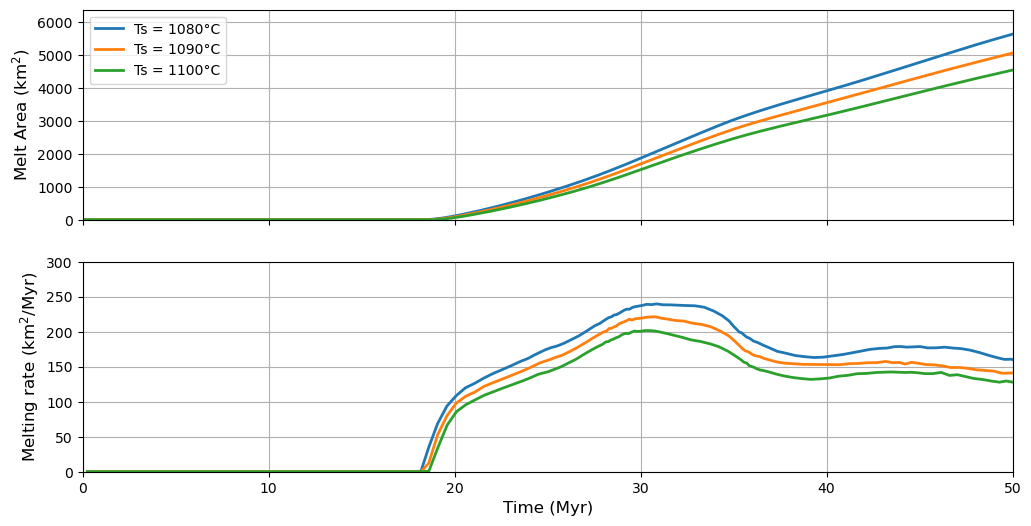

In [66]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for model_path in paths:
    model_name = model_path.split('/')[-1]

    time_evolution, melt_area_evolution = np.loadtxt(f"{model_path}/{model_name}_melt_area_evolution.txt", unpack=True)
    t_aux, dphi = np.loadtxt(f"{model_path}/{model_name}_melt_rate_evolution.txt", unpack=True)

    label = f"Ts = {model_name.split('_')[-1]}°C"
    axs[0].plot(time_evolution, melt_area_evolution, lw=2, label=label)
    axs[1].plot(t_aux, dphi, lw=2, label=model_name)


axs[1].set_xlabel('Time (Myr)', fontsize=12)
axs[0].set_ylabel('Melt Area (km$^2$)', fontsize=12)
axs[1].set_ylabel('Melting rate (km$^2$/Myr)', fontsize=12)

axs[0].set_xlim([time_evolution[0], 50])
axs[0].set_ylim([0, np.max(melt_area_evolution)*1.1])

# axs[1].set_xlim([t_aux[0], t_aux[-1]])
axs[1].set_ylim([0, 300])

axs[0].grid()
axs[1].grid()

axs[0].legend(loc='upper left', fontsize=10)

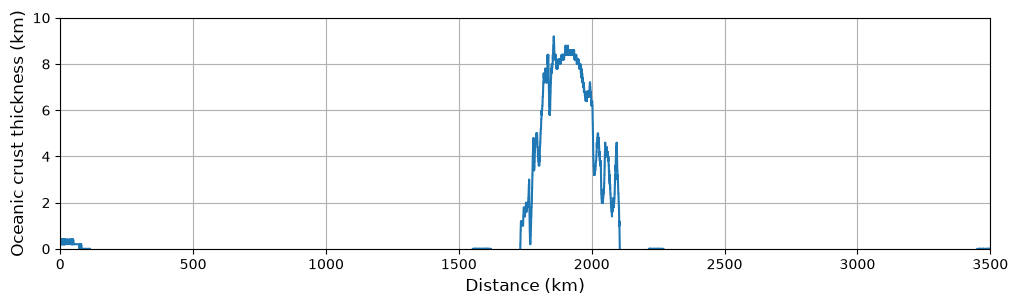

In [47]:
cond = (litho_data == 5) | (litho_data == 4)
dz = Lz/(Nz-1)
data2 = np.sum(cond, axis=0)/(5/dz) #cada elemento de meio km ta dividio em 5 partes de 100m, entao pra ter 1 km precisa de ter 10 subelementos
# dz
plt.figure(figsize=(12, 3))
plt.plot(np.arange(0, Lx, 0.2), data2[:-1]-40)
plt.xlim(0, Lx)
plt.ylim(0, 10)
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('Oceanic crust thickness (km)', fontsize=12)
plt.grid()

In [35]:
np.where(litho_data == 5)

(array([   0,    0,    0, ..., 2998, 2999, 3000], shape=(3515529,)),
 array([    0,     1,     2, ..., 17500, 17500, 17500], shape=(3515529,)))

(3001, 17501)

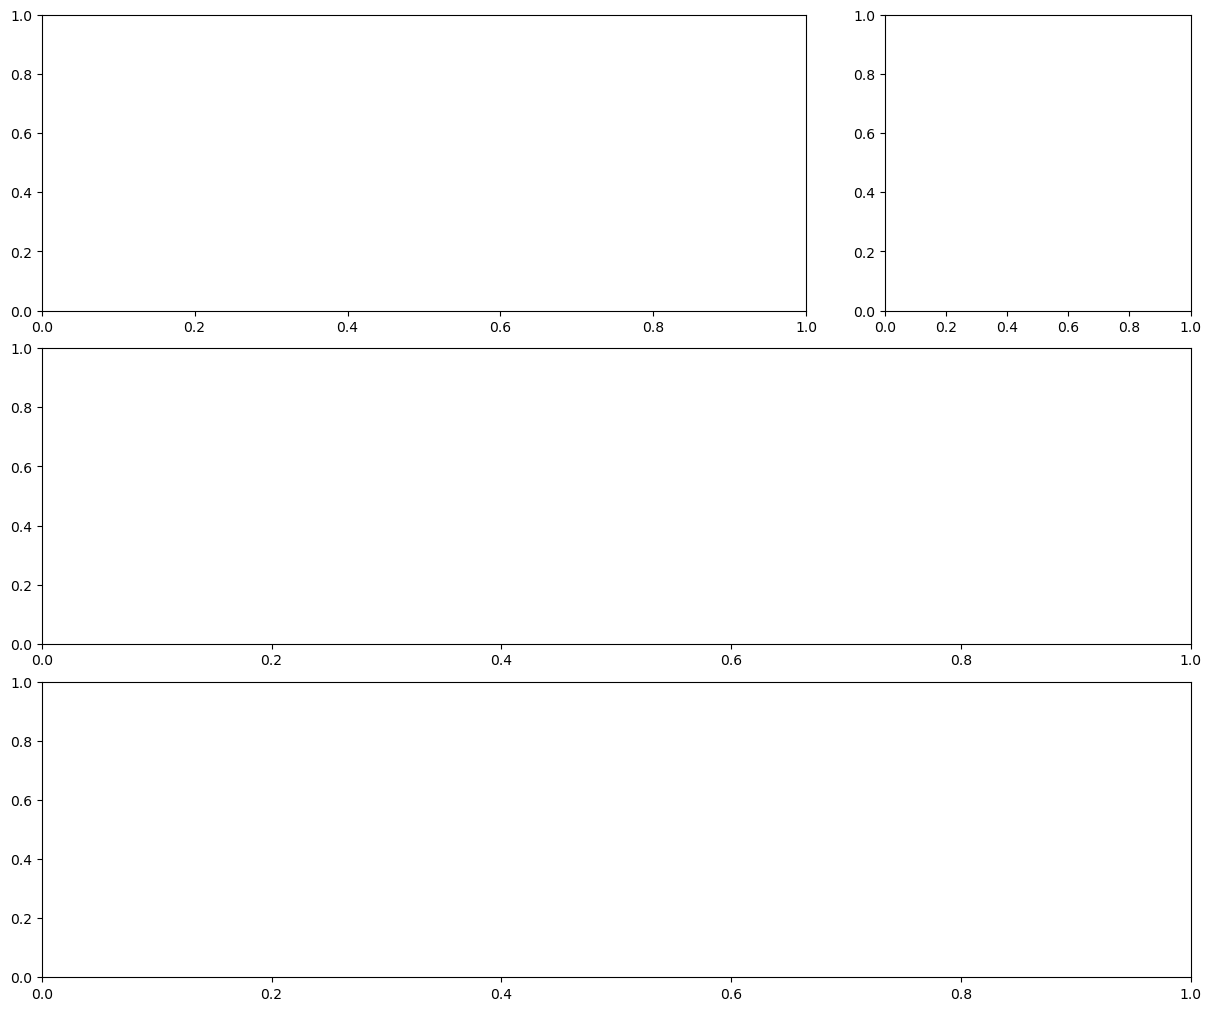

In [22]:
fig, axs = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True, gridspec_kw={'width_ratios': [1, 0.4]})
gs = axs[0, 0].get_gridspec()

# Remove os eixos da segunda linha
axs[1, 0].remove()
axs[1, 1].remove()
axs[2, 0].remove()
axs[2, 1].remove()
# # axs[1, 2].remove()
# # Cria um eixo ocupando toda a segunda linha
ax3 = fig.add_subplot(gs[1, :])
ax4 = fig.add_subplot(gs[2, :])

In [39]:

cond = (litho_data == 5) | (litho_data == 4)
dz = Lz/(Nz-1)
data2 = np.sum(cond, axis=0)/(5/dz) #cada elemento de meio km ta dividio em 5 partes de 100m, entao pra ter 1 km precisa de ter 10 subelementos
# dz

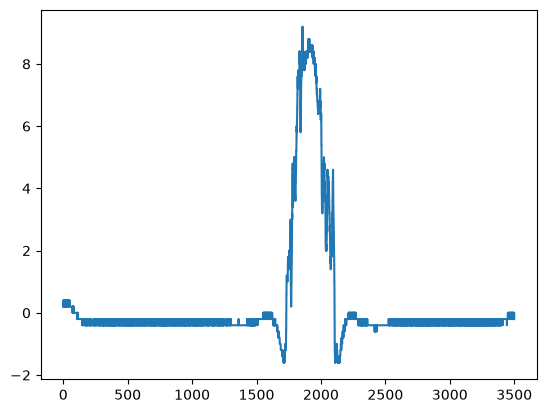